# Germany's Electricity Transition: Exploratory Data Analysis
Data source: Our World in Data energy dataset (annual data, 2000 to 2025)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

Matplotlib is building the font cache; this may take a moment.


# Load the data

In [2]:
df = pd.read_csv("data/owid_energy_selected.csv")

In [3]:
df.shape

(208, 19)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 19 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   country                                  208 non-null    str    
 1   year                                     208 non-null    int64  
 2   population                               208 non-null    float64
 3   electricity_generation                   208 non-null    float64
 4   electricity_demand                       208 non-null    float64
 5   net_elec_imports                         208 non-null    float64
 6   per_capita_electricity                   208 non-null    float64
 7   carbon_intensity_elec                    208 non-null    float64
 8   renewables_share_elec                    208 non-null    float64
 9   fossil_share_elec                        208 non-null    float64
 10  coal_share_elec                          208 non-null    floa

In [5]:
df.head()

,country,year,population,electricity_generation,electricity_demand,net_elec_imports,per_capita_electricity,carbon_intensity_elec,renewables_share_elec,fossil_share_elec,coal_share_elec,gas_share_elec,oil_share_elec,nuclear_share_elec,hydro_share_elec,wind_share_elec,solar_share_elec,biofuel_share_elec,other_renewables_share_elec_exc_biofuel
0,Denmark,2000,5339659.0,35.85,36.51,0.66,6713.912,627.89,15.537,84.463,46.499,24.463,13.501,0.0,0.084,11.827,0.0,3.626,0.0
1,Denmark,2001,5358825.0,37.54,36.97,-0.57,7005.267,630.79,15.583,84.417,47.469,24.694,12.254,0.0,0.080,11.481,0.0,4.022,0.0
2,Denmark,2002,5375967.0,39.10,37.03,-2.07,7273.110,618.67,17.366,82.634,46.701,24.527,11.407,0.0,0.077,12.481,0.0,4.808,0.0
3,Denmark,2003,5390621.0,45.97,37.42,-8.55,8527.774,651.51,17.555,82.445,55.058,21.231,6.156,0.0,0.044,12.095,0.0,5.417,0.0
4,Denmark,2004,5404594.0,40.24,37.37,-2.87,7445.518,581.26,23.683,76.317,46.397,24.702,5.219,0.0,0.075,16.377,0.0,7.232,0.0


# Data quality checks

In [6]:
df.isnull().sum()

country                                    0
year                                       0
population                                 0
electricity_generation                     0
electricity_demand                         0
net_elec_imports                           0
per_capita_electricity                     0
carbon_intensity_elec                      0
renewables_share_elec                      0
fossil_share_elec                          0
coal_share_elec                            0
gas_share_elec                             0
oil_share_elec                             0
nuclear_share_elec                         0
hydro_share_elec                           0
wind_share_elec                            0
solar_share_elec                           0
biofuel_share_elec                         0
other_renewables_share_elec_exc_biofuel    6
dtype: int64

In [7]:
# Which country and year have missing values?
missing = df[df.isnull().any(axis=1)][["country", "year"]]
print(missing.groupby("country")["year"].agg(["min", "max", "count"]))

                 min   max  count
country                          
United Kingdom  2020  2025      6


In [8]:
df.duplicated(subset=['country', 'year']).sum()

np.int64(0)

In [9]:
# Countries and years in the data
print(df["country"].unique())
print(df["year"].min(), "to", df["year"].max())

<StringArray>
[       'Denmark',         'France',        'Germany',          'Italy',
    'Netherlands',         'Poland',          'Spain', 'United Kingdom']
Length: 8, dtype: str
2000 to 2025


In [10]:
# Do the generation shares add up to about 100 percent?
share_cols = ["coal_share_elec", "gas_share_elec", "oil_share_elec", "nuclear_share_elec",
              "hydro_share_elec", "wind_share_elec", "solar_share_elec",
              "biofuel_share_elec", "other_renewables_share_elec_exc_biofuel"]
df["share_total"] = df[share_cols].sum(axis=1)
print(df["share_total"].describe().round(2))

count    208.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: share_total, dtype: float64


# Focus on Germany

In [11]:
ger = df[df["country"] == "Germany"].copy()
ger = ger.set_index("year")
ger[["electricity_generation", "renewables_share_elec", "coal_share_elec",
     "nuclear_share_elec", "carbon_intensity_elec"]].round(1).loc[[2000, 2010, 2020, 2025]]

,electricity_generation,renewables_share_elec,coal_share_elec,nuclear_share_elec,carbon_intensity_elec
year,,,,,
2000,569.0,6.2,52.1,29.8,573.2
2010,624.2,16.9,42.1,22.5,516.6
2020,566.8,44.4,23.7,11.4,355.6
2025,500.5,59.1,20.6,0.0,329.6


# 1. How did the electricity mix change?

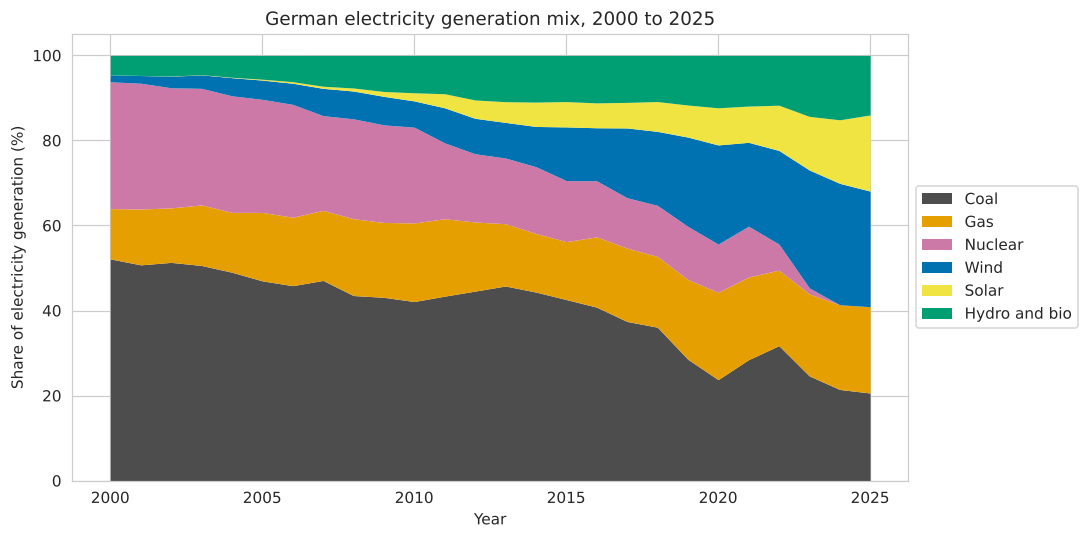

In [12]:
# Group the small sources so the chart stays readable
mix = pd.DataFrame({
    "Coal": ger["coal_share_elec"],
    "Gas": ger["gas_share_elec"] + ger["oil_share_elec"],
    "Nuclear": ger["nuclear_share_elec"],
    "Wind": ger["wind_share_elec"],
    "Solar": ger["solar_share_elec"],
    "Hydro and bio": ger["hydro_share_elec"] + ger["biofuel_share_elec"]
                     + ger["other_renewables_share_elec_exc_biofuel"],
})

colors = ["#4d4d4d", "#e69f00", "#cc79a7", "#0072b2", "#f0e442", "#009e73"]
mix.plot.area(figsize=(10, 5), color=colors, linewidth=0)
plt.title("German electricity generation mix, 2000 to 2025")
plt.ylabel("Share of electricity generation (%)")
plt.xlabel("Year")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

In [13]:
print(mix.round(1).loc[[2000, 2010, 2020, 2025]])

      Coal   Gas  Nuclear  Wind  Solar  Hydro and bio
year                                                 
2000  52.1  11.8     29.8   1.6    0.0            4.6
2010  42.1  18.5     22.5   6.2    1.9            8.8
2020  23.7  20.5     11.4  23.3    8.7           12.3
2025  20.6  20.3      0.0  27.2   17.9           14.0


# 2. When did renewables overtake coal?

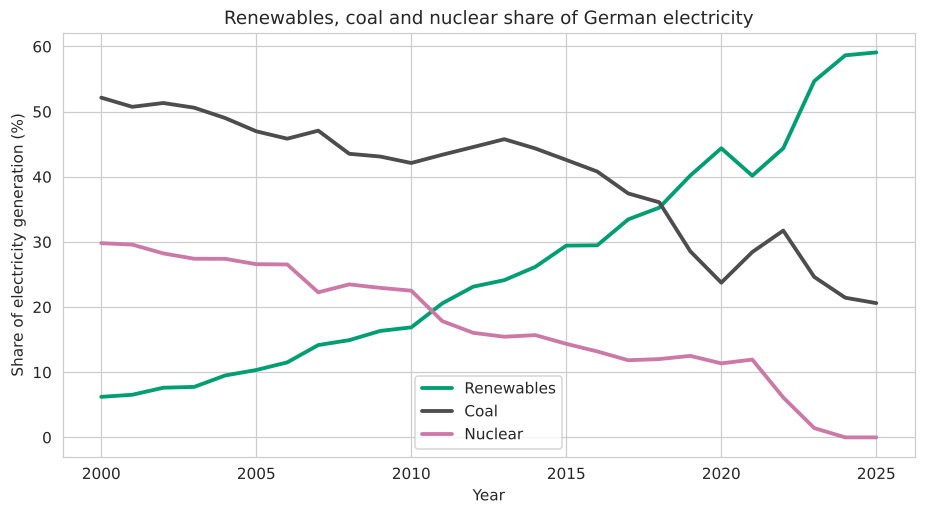

Renewables first produced more than coal in: 2019


In [14]:
plt.figure(figsize=(10, 5))
plt.plot(ger.index, ger["renewables_share_elec"], label="Renewables", color="#009e73", linewidth=2.5)
plt.plot(ger.index, ger["coal_share_elec"], label="Coal", color="#4d4d4d", linewidth=2.5)
plt.plot(ger.index, ger["nuclear_share_elec"], label="Nuclear", color="#cc79a7", linewidth=2.5)
plt.title("Renewables, coal and nuclear share of German electricity")
plt.ylabel("Share of electricity generation (%)")
plt.xlabel("Year")
plt.legend()
plt.show()

first_year = ger[ger["renewables_share_elec"] > ger["coal_share_elec"]].index.min()
print("Renewables first produced more than coal in:", first_year)

# 3. Wind and solar growth

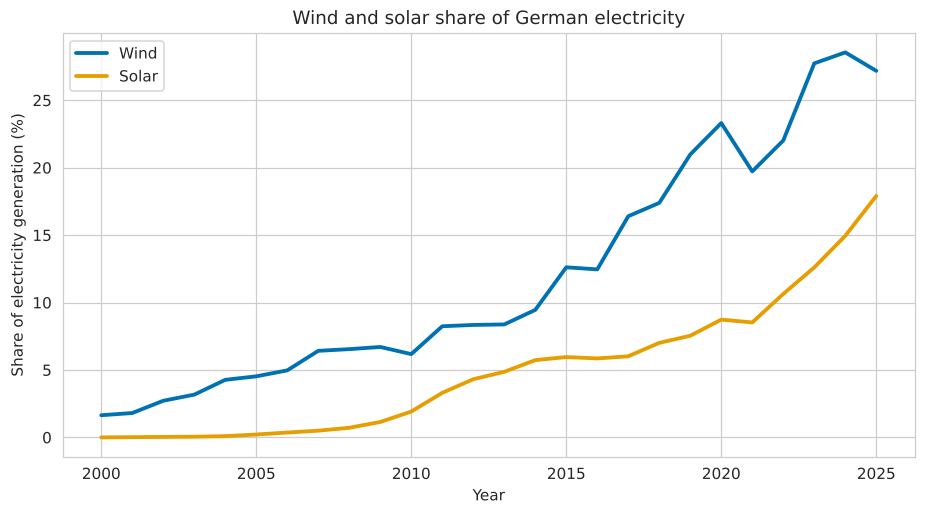

year
2000     1.6
2010     8.1
2020    32.0
2025    45.1
Name: wind_solar_share, dtype: float64


In [15]:
plt.figure(figsize=(10, 5))
plt.plot(ger.index, ger["wind_share_elec"], label="Wind", color="#0072b2", linewidth=2.5)
plt.plot(ger.index, ger["solar_share_elec"], label="Solar", color="#e69f00", linewidth=2.5)
plt.title("Wind and solar share of German electricity")
plt.ylabel("Share of electricity generation (%)")
plt.xlabel("Year")
plt.legend()
plt.show()

ger["wind_solar_share"] = ger["wind_share_elec"] + ger["solar_share_elec"]
print(ger["wind_solar_share"].round(1).loc[[2000, 2010, 2020, 2025]])

# 4. Carbon intensity and the coal share

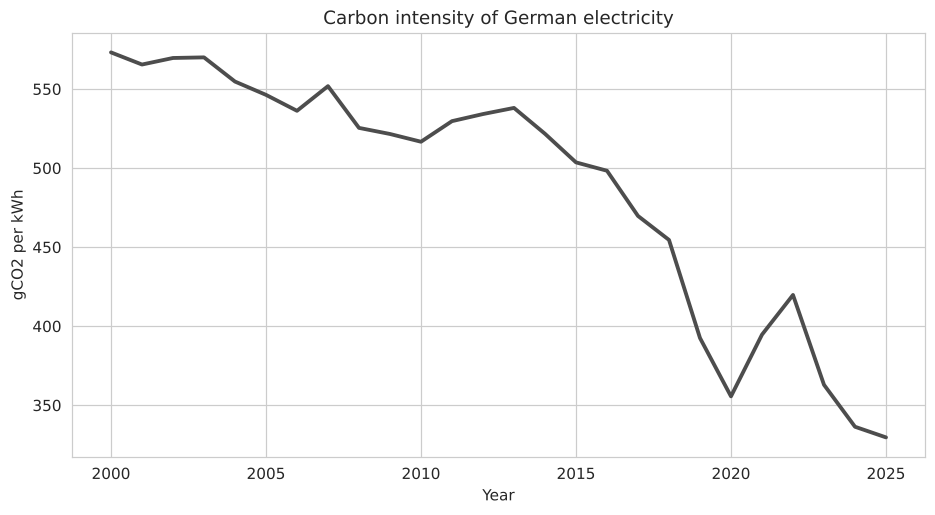

Carbon intensity 2000: 573 gCO2/kWh
Carbon intensity 2025: 330 gCO2/kWh
Change: -42%


In [16]:
plt.figure(figsize=(10, 5))
plt.plot(ger.index, ger["carbon_intensity_elec"], color="#4d4d4d", linewidth=2.5)
plt.title("Carbon intensity of German electricity")
plt.ylabel("gCO2 per kWh")
plt.xlabel("Year")
plt.show()

change = ger.loc[2025, "carbon_intensity_elec"] / ger.loc[2000, "carbon_intensity_elec"] - 1
print(f"Carbon intensity 2000: {ger.loc[2000, 'carbon_intensity_elec']:.0f} gCO2/kWh")
print(f"Carbon intensity 2025: {ger.loc[2025, 'carbon_intensity_elec']:.0f} gCO2/kWh")
print(f"Change: {change:.0%}")

Correlation coal share vs carbon intensity: 1.00


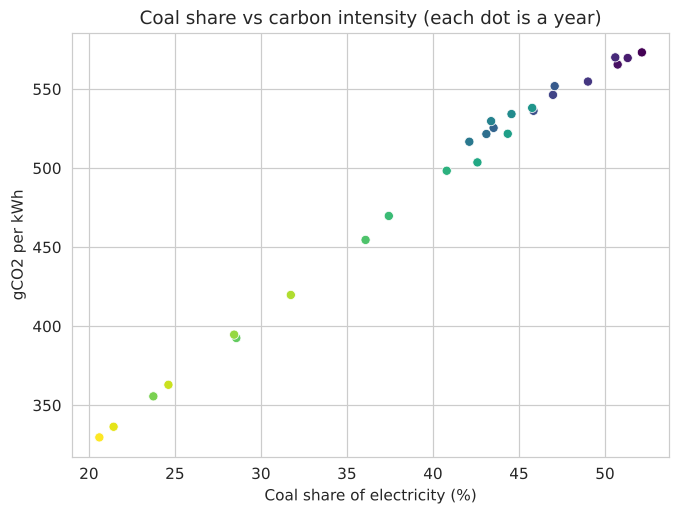

In [17]:
# How strongly does the coal share explain carbon intensity?
corr = ger["coal_share_elec"].corr(ger["carbon_intensity_elec"])
print(f"Correlation coal share vs carbon intensity: {corr:.2f}")

plt.figure(figsize=(7, 5))
sns.scatterplot(x=ger["coal_share_elec"], y=ger["carbon_intensity_elec"], hue=ger.index, palette="viridis", legend=False)
plt.title("Coal share vs carbon intensity (each dot is a year)")
plt.xlabel("Coal share of electricity (%)")
plt.ylabel("gCO2 per kWh")
plt.show()

# 5. Nuclear phase-out: from net exporter to net importer

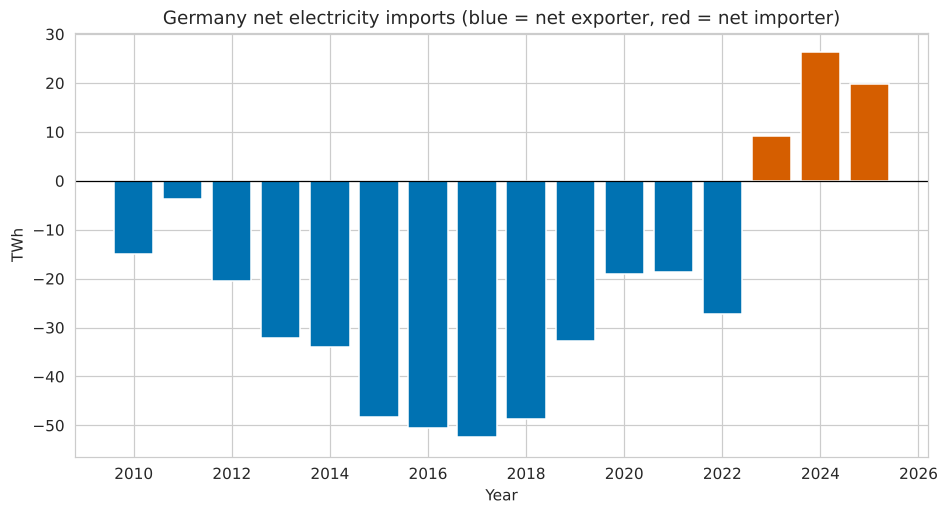

year
2010   -15.0
2015   -48.3
2020   -19.0
2022   -27.3
2023     9.2
2024    26.3
2025    19.8
Name: net_elec_imports, dtype: float64


In [18]:
# Negative value = Germany exported more electricity than it imported
imports = ger.loc[2010:, "net_elec_imports"]
bar_colors = ["#0072b2" if v < 0 else "#d55e00" for v in imports]

plt.figure(figsize=(10, 5))
plt.bar(imports.index, imports.values, color=bar_colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Germany net electricity imports (blue = net exporter, red = net importer)")
plt.ylabel("TWh")
plt.xlabel("Year")
plt.show()

print(imports.round(1).loc[[2010, 2015, 2020, 2022, 2023, 2024, 2025]])

# 6. Crisis years: 2020 to 2023

In [19]:
crisis = ger.loc[2019:2023, ["electricity_generation", "coal_share_elec", "gas_share_elec",
                              "nuclear_share_elec", "renewables_share_elec", "carbon_intensity_elec"]]
print(crisis.round(1))

      electricity_generation  coal_share_elec  gas_share_elec  \
year                                                            
2019                   600.1             28.6            15.0   
2020                   566.8             23.7            16.8   
2021                   578.8             28.4            15.6   
2022                   566.9             31.7            13.9   
2023                   506.7             24.6            15.1   

      nuclear_share_elec  renewables_share_elec  carbon_intensity_elec  
year                                                                    
2019                12.5                   40.2                  392.5  
2020                11.4                   44.4                  355.6  
2021                11.9                   40.2                  394.6  
2022                 6.1                   44.4                  419.7  
2023                 1.4                   54.7                  362.9  


# 7. Demand: is Germany using less electricity?

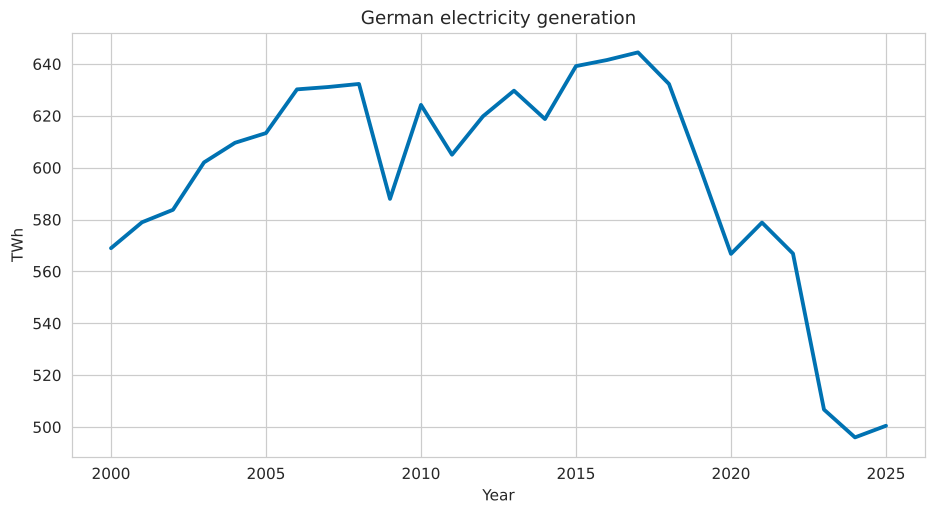

Peak generation: 644 TWh in 2017
2025: 500 TWh
Change from the peak: -22%


In [20]:
plt.figure(figsize=(10, 5))
plt.plot(ger.index, ger["electricity_generation"], color="#0072b2", linewidth=2.5)
plt.title("German electricity generation")
plt.ylabel("TWh")
plt.xlabel("Year")
plt.show()

peak = ger["electricity_generation"].idxmax()
print(f"Peak generation: {ger['electricity_generation'].max():.0f} TWh in {peak}")
print(f"2025: {ger.loc[2025, 'electricity_generation']:.0f} TWh")
print(f"Change from the peak: {ger.loc[2025, 'electricity_generation'] / ger['electricity_generation'].max() - 1:.0%}")

# 8. Germany compared with seven European countries (2024)

In [21]:
# 2024 is used because it is a full year for all countries
peers = df[df["year"] == 2024].set_index("country")
peers[["renewables_share_elec", "coal_share_elec", "gas_share_elec", "nuclear_share_elec",
       "wind_share_elec", "solar_share_elec", "carbon_intensity_elec"]].round(1).sort_values("carbon_intensity_elec")

,renewables_share_elec,coal_share_elec,gas_share_elec,nuclear_share_elec,wind_share_elec,solar_share_elec,carbon_intensity_elec
country,,,,,,,
France,27.2,0.2,3.2,67.7,8.1,4.4,40.5
Denmark,89.2,5.0,2.6,0.0,58.2,10.8,131.8
Spain,57.3,0.9,18.6,19.4,22.1,20.7,146.2
United Kingdom,50.6,0.7,30.4,14.3,29.3,5.2,216.5
Netherlands,50.7,6.1,36.2,2.9,27.4,17.8,250.7
Italy,50.2,1.5,44.3,0.0,8.3,13.5,281.4
Germany,58.6,21.4,15.8,0.0,28.5,14.9,336.4
Poland,31.1,54.3,11.9,0.0,15.0,10.3,608.2


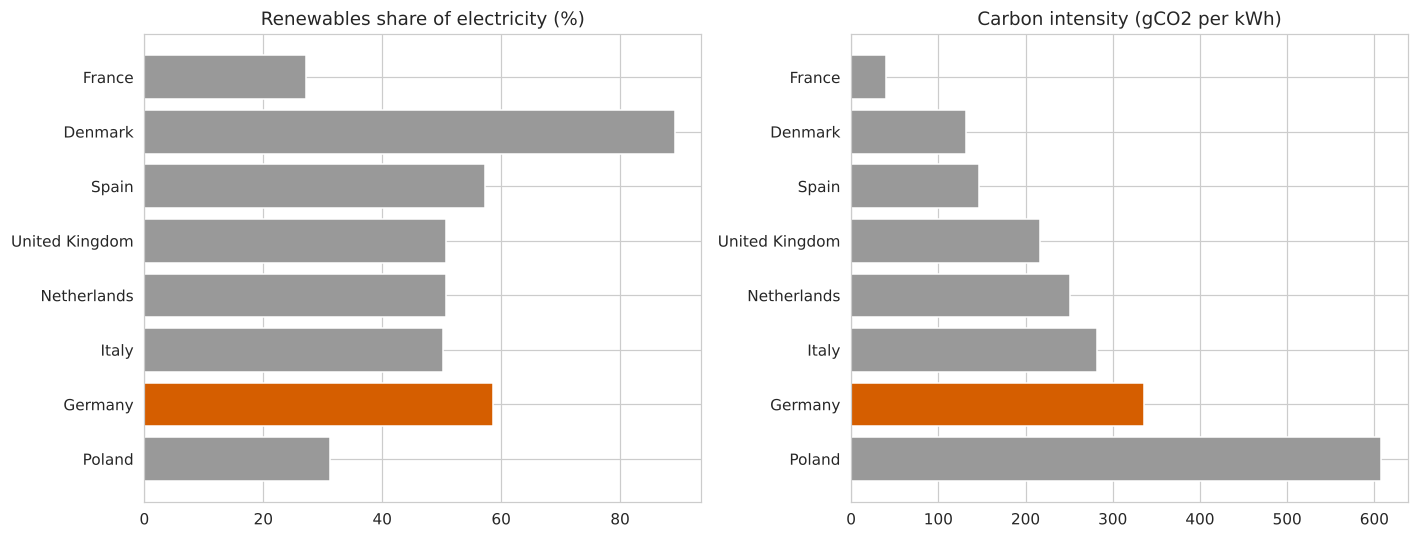

In [22]:
order = peers.sort_values("carbon_intensity_elec").index
bar_colors = ["#d55e00" if c == "Germany" else "#999999" for c in order]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(order, peers.loc[order, "renewables_share_elec"], color=bar_colors)
axes[0].set_title("Renewables share of electricity (%)")
axes[0].invert_yaxis()

axes[1].barh(order, peers.loc[order, "carbon_intensity_elec"], color=bar_colors)
axes[1].set_title("Carbon intensity (gCO2 per kWh)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

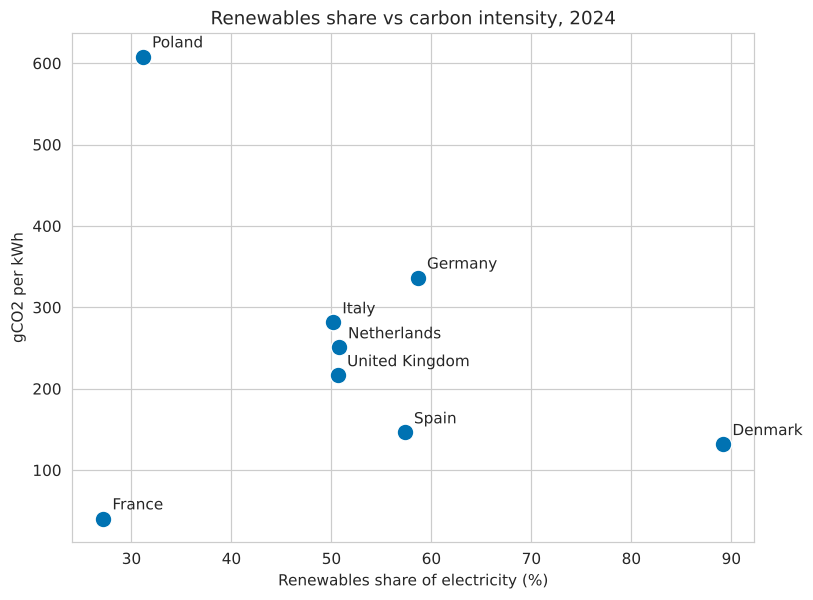

In [23]:
# Renewables share vs carbon intensity: more renewables does not always mean low carbon
plt.figure(figsize=(8, 6))
sns.scatterplot(x=peers["renewables_share_elec"], y=peers["carbon_intensity_elec"], s=120, color="#0072b2")
for country, row in peers.iterrows():
    plt.annotate(country, (row["renewables_share_elec"], row["carbon_intensity_elec"]),
                 textcoords="offset points", xytext=(6, 6))
plt.title("Renewables share vs carbon intensity, 2024")
plt.xlabel("Renewables share of electricity (%)")
plt.ylabel("gCO2 per kWh")
plt.show()

# Summary of key numbers

In [24]:
print("Renewables share: ", round(ger.loc[2000, "renewables_share_elec"], 1), "% (2000) ->", round(ger.loc[2025, "renewables_share_elec"], 1), "% (2025)")
print("Coal share:       ", round(ger.loc[2000, "coal_share_elec"], 1), "% (2000) ->", round(ger.loc[2025, "coal_share_elec"], 1), "% (2025)")
print("Nuclear share:    ", round(ger.loc[2000, "nuclear_share_elec"], 1), "% (2000) ->", round(ger.loc[2025, "nuclear_share_elec"], 1), "% (2025)")
print("Wind + solar:     ", round(ger.loc[2000, "wind_solar_share"], 1), "% (2000) ->", round(ger.loc[2025, "wind_solar_share"], 1), "% (2025)")
print("Carbon intensity: ", round(ger.loc[2000, "carbon_intensity_elec"]), "->", round(ger.loc[2025, "carbon_intensity_elec"]), "gCO2/kWh")

Renewables share:  6.2 % (2000) -> 59.1 % (2025)
Coal share:        52.1 % (2000) -> 20.6 % (2025)
Nuclear share:     29.8 % (2000) -> 0.0 % (2025)
Wind + solar:      1.6 % (2000) -> 45.1 % (2025)
Carbon intensity:  573 -> 330 gCO2/kWh
